# HanuAi ML Assessment — Task 1: Web Scraping & Sentiment Analysis

**Product:** Keurig® K-Café™ Single Serve Coffee Maker with Milk Frother — Dark Charcoal
**BestBuy Canada SKU:** `13787125` · [product reviews page](https://www.bestbuy.ca/en-ca/product/13787125/review)
**Why this product:** 321 public reviews (well above the 50 minimum) with a genuinely mixed rating spread
(≈21% of reviews are 1–3★), so there is real signal for satisfaction *and* dissatisfaction drivers.

### Pipeline overview
| Step | What happens | Tooling |
|---|---|---|
| 0. Compliance | Check `robots.txt` before touching any URL; only public review data is collected; polite delays | `urllib.robotparser` |
| 1. Scrape (UI path) | Headless Chrome opens the review page, applies each **Sort filter** (Most Relevant, Most Helpful, Newest, Oldest, Highest Rating, Lowest Rating) and clicks **“Show More”** until every review is loaded | Selenium + BeautifulSoup |
| 2. Enrich (API path) | The page’s own public JSON endpoint (the request “Show More” fires) is paginated for every sort order to get the official review ID, helpful votes and verified-purchase flag. Doubles as a fallback if the browser path is blocked | `requests` + retry/backoff |
| 3. Merge & clean | Union of all filters → de-duplicate → standardise fields (Date = YYYY-MM-DD, Rating /5, Source …) | pandas |
| 4. Sentiment | Overall sentiment with a multilingual review-trained transformer (validated against star ratings, VADER as baseline) + **aspect-based categorisation** (e.g. `['Good Design & Quality (Pos)']`) | HF Transformers, Sentence-Transformers, VADER |
| 5. Insights | Satisfaction / dissatisfaction drivers, star-impact of each aspect, trends, recommendations | pandas, scikit-learn, matplotlib |
| 6. Export | Excel (multi-sheet, formatted) + CSV | openpyxl |

In [1]:
# ----------------------------------------------------------------------------------
# Imports & configuration
# ----------------------------------------------------------------------------------
import re, time, json, random, hashlib, warnings
from pathlib import Path
from datetime import datetime
from urllib import robotparser

import numpy as np
import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

SKU          = "13787125"                                         # BestBuy.ca product id
REVIEW_URL   = f"https://www.bestbuy.ca/en-ca/product/{SKU}/review"
API_URL      = f"https://www.bestbuy.ca/api/v2/json/reviews/{SKU}"
USER_AGENT   = ("Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                "(KHTML, like Gecko) Chrome/130.0 Safari/537.36")

# Each UI sort filter (value of <select id="Sort"> on the page) and the equivalent API params.
SORT_FILTERS = {
    "Most Relevant":  {"ui": "relevancy",     "api": {"sortBy": "relevancy"}},
    "Most Helpful":   {"ui": "helpfulness",   "api": {"sortBy": "helpfulness", "sortDir": "desc"}},
    "Newest":         {"ui": "newest",        "api": {"sortBy": "date",        "sortDir": "desc"}},
    "Oldest":         {"ui": "oldest",        "api": {"sortBy": "date",        "sortDir": "asc"}},
    "Highest Rating": {"ui": "highestRating", "api": {"sortBy": "rating",      "sortDir": "desc"}},
    "Lowest Rating":  {"ui": "lowestRating",  "api": {"sortBy": "rating",      "sortDir": "asc"}},
}

BASE_DIR   = Path.cwd()
OUT_DIR    = BASE_DIR / "outputs";  OUT_DIR.mkdir(exist_ok=True)
FIG_DIR    = BASE_DIR / "figures";  FIG_DIR.mkdir(exist_ok=True)
RAW_UI_DIR = OUT_DIR / "raw_selenium";  RAW_UI_DIR.mkdir(exist_ok=True)   # one checkpoint file per filter
RAW_API_DIR = OUT_DIR / "raw_api";      RAW_API_DIR.mkdir(exist_ok=True)
FORCE_RESCRAPE = False                               # True = ignore checkpoints and scrape everything live again

MIN_DELAY, MAX_DELAY = 2.0, 4.0                      # polite randomised delay between requests/clicks (seconds)
FILTER_COOLDOWN      = 45                            # pause between filters - BestBuy throttles after ~1,000 rapid card loads
MAX_SHOW_MORE_CLICKS = 200                           # safety cap per filter
COMPLETE_RATIO       = 0.95                          # a filter counts as complete once it has >=95% of the site-reported total

## 0. Compliance check — `robots.txt`
The script only proceeds if BestBuy’s `robots.txt` permits the URLs we use. Product/review pages are explicitly
`Allow: /en-ca/product/` and the review JSON endpoint is not disallowed. We only collect what any visitor sees publicly
(no login, no personal data beyond the public display name), throttle requests, and identify as a normal browser.

In [2]:
# Fetch robots.txt ourselves: BestBuy's edge silently hangs requests that carry Python's default
# urllib user-agent, so RobotFileParser.read() would block forever. Browser UA + timeout instead.
robots_txt = requests.get("https://www.bestbuy.ca/robots.txt", headers={"User-Agent": USER_AGENT}, timeout=30).text
rp = robotparser.RobotFileParser()
rp.parse(robots_txt.splitlines())
for url in [REVIEW_URL, API_URL]:
    allowed = rp.can_fetch("*", url)
    print(f"{'ALLOWED ' if allowed else 'BLOCKED '} {url}")
    assert allowed, "robots.txt disallows this URL - stop."

ALLOWED  https://www.bestbuy.ca/en-ca/product/13787125/review
ALLOWED  https://www.bestbuy.ca/api/v2/json/reviews/13787125


## 1. Scraping path A — Selenium (applies the UI filters and clicks “Show More”)
* `build_driver()` – headless Chrome with a realistic UA and window size.
* `apply_sort()` – selects a filter in the **Sort** dropdown and waits until the review list re-renders.
* `load_all_reviews()` – clicks **Show More** repeatedly (scroll into view → JS click → wait for card count to grow) until
  the button disappears; random delays between clicks; retries a click if the DOM re-renders mid-click.
* `parse_review_cards()` – BeautifulSoup parses each review card into a dictionary.

In [3]:
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import Select, WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from selenium.common.exceptions import TimeoutException, StaleElementReferenceException

CARD_CSS = "[class*=reviewItem_]"           # BestBuy uses hashed CSS-module class names -> match on the stable prefix

def polite_sleep():
    time.sleep(random.uniform(MIN_DELAY, MAX_DELAY))

def build_driver(headless=True):
    opts = webdriver.ChromeOptions()
    if headless:
        opts.add_argument("--headless=new")
    opts.add_argument("--window-size=1400,2000")
    opts.add_argument(f"user-agent={USER_AGENT}")
    opts.add_argument("--disable-blink-features=AutomationControlled")   # avoid the obvious webdriver flag
    opts.add_argument("--lang=en-CA")
    return webdriver.Chrome(options=opts)                                 # Selenium Manager resolves chromedriver

def _cards(driver):
    return driver.find_elements(By.CSS_SELECTOR, CARD_CSS)

def apply_sort(driver, ui_value, timeout=15):
    # Select a sort filter and wait for the list to re-render (old first card goes stale or its text changes).
    old_first = _cards(driver)[0]
    old_text  = old_first.text
    Select(driver.find_element(By.ID, "Sort")).select_by_value(ui_value)
    try:
        WebDriverWait(driver, timeout).until(
            lambda d: EC.staleness_of(old_first)(d) or (_cards(d) and _cards(d)[0].text != old_text))
    except TimeoutException:
        pass        # some filters legitimately return the same first review (e.g. Relevant vs Helpful)
    time.sleep(1.5)

def _show_more_button(driver):
    for b in driver.find_elements(By.TAG_NAME, "button"):
        try:
            if b.text.strip().lower() == "show more" and b.is_displayed():
                return b
        except StaleElementReferenceException:
            continue
    return None

class ThrottledError(RuntimeError):
    # Raised when "Show More" stops returning reviews - the signature of server-side rate limiting.
    pass

def load_all_reviews(driver, expected_total=None, max_clicks=MAX_SHOW_MORE_CLICKS):
    # Pagination: keep clicking "Show More" until it disappears (or the safety cap is hit).
    clicks = 0
    while clicks < max_clicks:
        btn = _show_more_button(driver)
        if btn is None:
            break
        n_before = len(_cards(driver))
        for attempt in range(3):                       # retry mechanism for flaky clicks / slow responses
            try:
                driver.execute_script("arguments[0].scrollIntoView({block:'center'}); arguments[0].click();", btn)
                WebDriverWait(driver, 20).until(lambda d: len(_cards(d)) > n_before)
                break
            except (TimeoutException, StaleElementReferenceException):
                time.sleep(3 * (attempt + 1))          # linear back-off
                btn = _show_more_button(driver)
                if btn is None:
                    break
        else:
            raise ThrottledError(f"'Show More' stuck at {n_before} reviews after 3 attempts")
        clicks += 1
        if expected_total and len(_cards(driver)) >= expected_total:
            break
        polite_sleep()
    return clicks

def parse_review_cards(html):
    # Turn every review card in the rendered page into a dict of raw fields.
    soup, rows = BeautifulSoup(html, "html.parser"), []
    for card in soup.select(CARD_CSS):
        rating_txt = card.select_one("p.sr-only")
        m = re.search(r"(\d(?:\.\d)?) out of 5", rating_txt.get_text() if rating_txt else "")
        date_el = card.select_one("[data-date]")
        # Syndicated (keurig.ca) cards carry schema.org itemprops; native bestbuy.ca cards don't -> structural fallback
        body    = card.select_one("[itemprop=reviewBody]") or card.select_one("[class*=reviewContent_]")
        name    = (card.select_one("[itemprop=author] [itemprop=name]") or
                   card.select_one("[class*=author_] > span > span") or card.select_one("[class*=author_] > span"))
        title   = card.select_one("h3")
        text    = card.get_text(" ", strip=True)
        src     = re.search(r"originally posted on ([\w\.-]+)", text, re.I)
        rec     = ("Yes" if re.search(r"I would recommend this", text) else
                   "No"  if re.search(r"I would not recommend this", text) else None)
        # Native BestBuy reviews also expose "key consideration" sub-ratings (Quality / Value / Ease of Use)
        subs = {}
        for leg in card.select("legend[data-automation=attribute-label]"):
            val = leg.select_one("[data-automation=selected-rating]")
            key = leg.get_text(" ", strip=True).replace(val.get_text(strip=True), "").strip(" :") if val else None
            if key and val:
                subs[f"sub_rating_{key.lower().replace(' ', '_')}"] = val.get_text(strip=True)
        rows.append({**subs,
            "reviewer_name":   name.get_text(strip=True) if name else None,
            "rating":          float(m.group(1)) if m else None,
            "title":           title.get_text(" ", strip=True) if title else None,
            "review_text":     body.get_text("\n", strip=True) if body else None,
            "submission_time": date_el["data-date"] if date_el else None,
            "source":          src.group(1).lower() if src else "bestbuy.ca",
            "recommended":     rec,
        })
    return rows

def open_review_page(driver, timeout=45):
    driver.get(REVIEW_URL)
    WebDriverWait(driver, timeout).until(lambda d: len(_cards(d)) > 0)

def _checkpoint(folder, label):
    return folder / (re.sub(r"\W+", "_", label.lower()).strip("_") + ".csv")

def scrape_with_selenium(filters=SORT_FILTERS, expected_total=None, max_attempts=3):
    # * One page load; filters are switched in-page via the Sort dropdown (which resets the list to the first 10).
    # * Each completed filter is checkpointed to its own CSV, so a re-run only scrapes what is missing.
    # * Throttling (stalled "Show More" or an incomplete list) -> close browser, cool down 90s/180s, retry.
    #   After max_attempts the best partial result is kept and the API path fills the gap.
    driver, frames, need_sort = None, [], False
    try:
        for label, cfg in filters.items():
            ckpt = _checkpoint(RAW_UI_DIR, label)
            if ckpt.exists() and not FORCE_RESCRAPE:
                cached = pd.read_csv(ckpt)
                if not expected_total or len(cached) >= COMPLETE_RATIO * expected_total:
                    print(f"[{label:<15}] checkpoint -> {len(cached):>4} reviews (cached)")
                    frames.append(cached); continue
            best = None
            for attempt in range(1, max_attempts + 1):
                try:
                    if driver is None:
                        driver = build_driver(); open_review_page(driver); need_sort = False
                    if need_sort or cfg["ui"] != "relevancy":
                        apply_sort(driver, cfg["ui"])
                    need_sort = True
                    t0 = time.time()
                    clicks = load_all_reviews(driver, expected_total)
                    html = driver.page_source
                    # keep the rendered HTML so parser fixes can be re-applied offline without re-hitting the site
                    ckpt.with_suffix(".html").write_text(html, encoding="utf-8")
                    rows = parse_review_cards(html)
                    print(f"[{label:<15}] {clicks:>3} 'Show More' clicks -> {len(rows):>4} reviews  ({time.time()-t0:5.1f}s)")
                    if best is None or len(rows) > len(best):
                        best = rows
                    if expected_total and len(rows) < COMPLETE_RATIO * expected_total:
                        raise ThrottledError(f"only {len(rows)}/{expected_total} reviews loaded")
                    break
                except Exception as e:
                    wait = 90 * attempt
                    print(f"[{label:<15}] attempt {attempt}: {type(e).__name__} - {str(e)[:80]} -> cooling down {wait}s")
                    if driver is not None:
                        driver.quit(); driver = None
                    if attempt < max_attempts:
                        time.sleep(wait)
            if best:
                fdf = pd.DataFrame(best)
                fdf["filter"], fdf["rank_in_filter"] = label, range(1, len(fdf) + 1)
                fdf["scraped_at"] = datetime.now().isoformat(timespec="seconds")
                fdf.to_csv(ckpt, index=False)
                frames.append(fdf)
            time.sleep(FILTER_COOLDOWN)
    finally:
        if driver is not None:
            driver.quit()
    return pd.concat(frames, ignore_index=True)

## 2. Scraping path B — public review JSON (enrichment + fallback)
When “Show More” is clicked, the page calls `api/v2/json/reviews/<sku>?page=N`. Calling it directly gives the **official
review ID** (used as primary key), helpful/unhelpful vote counts and the verified-purchaser flag, none of which are reliably in
the HTML. A `requests.Session` with **exponential back-off retries** (on 429/5xx) and random delays keeps the load light;
if Selenium is ever blocked (CAPTCHA / bot wall), this path alone still yields the full dataset.

In [4]:
def make_session():
    s = requests.Session()
    retry = Retry(total=5, read=1, backoff_factor=1.5,                       # 1.5s, 3s, 6s, 12s ... between retries
                  status_forcelist=[429, 500, 502, 503, 504],
                  allowed_methods=["GET"], respect_retry_after_header=True)
    s.mount("https://", HTTPAdapter(max_retries=retry))
    s.headers.update({"User-Agent": USER_AGENT, "Accept": "application/json",
                      "Accept-Language": "en-CA,en;q=0.9", "Referer": REVIEW_URL})
    return s

def get_json(session, params, attempts=4, timeout=60):
    # Retry wrapper for read timeouts / connection resets (urllib3.Retry covers status codes).
    for attempt in range(1, attempts + 1):
        try:
            resp = session.get(API_URL, params=params, timeout=timeout)
            resp.raise_for_status()
            return resp.json()
        except requests.RequestException as e:
            if attempt == attempts:
                raise
            wait = 30 * attempt
            print(f"   request failed ({type(e).__name__}), retry {attempt}/{attempts-1} in {wait}s")
            time.sleep(wait)

def fetch_api_reviews(session, extra_params, page_size=100):
    # Paginate through every page for one sort order.
    page, rows, total_pages, data = 1, [], 1, {}
    while page <= total_pages:
        params = {"source": "all", "lang": "en-CA", "pageSize": page_size, "page": page, **extra_params}
        data = get_json(session, params)
        total_pages = data.get("totalPages", 1)
        rows.extend(data.get("reviews", []))
        page += 1
        polite_sleep()
    return rows, data.get("RatingSummary", {})

def scrape_with_api(filters=SORT_FILTERS):
    session, frames = make_session(), []
    for label, cfg in filters.items():
        ckpt = _checkpoint(RAW_API_DIR, label)
        if ckpt.exists() and not FORCE_RESCRAPE:
            df = pd.read_csv(ckpt); print(f"[{label:<15}] checkpoint -> {len(df):>4} reviews (cached)")
        else:
            try:
                rows, _ = fetch_api_reviews(session, cfg["api"])
            except requests.RequestException as e:
                print(f"[{label:<15}] API failed after retries ({type(e).__name__}) - skipped"); continue
            df = pd.json_normalize(rows)
            df["filter"], df["rank_in_filter"] = label, range(1, len(df) + 1)
            df.to_csv(ckpt, index=False)
            print(f"[{label:<15}] API pages -> {len(df):>4} reviews")
        frames.append(df)
    return pd.concat(frames, ignore_index=True)

In [5]:
# ----------------------------------------------------------------------------------
# Run both scrapers (or load the cached raw files if they already exist)
# ----------------------------------------------------------------------------------
session = make_session()
meta = get_json(session, {"source": "all", "lang": "en-CA", "pageSize": 1, "page": 1})
EXPECTED_TOTAL = meta["total"]
rating_summary = meta["RatingSummary"]
print(f"BestBuy reports {EXPECTED_TOTAL} reviews, average {rating_summary['OverallAverageScore']}★, "
      f"{rating_summary['RecommendedCount']} would recommend / {rating_summary['NotRecommendedCount']} would not\n")

print("Selenium (UI filters + 'Show More'):")
ui_raw = scrape_with_selenium(expected_total=EXPECTED_TOTAL)
print("\nJSON endpoint (enrichment / fallback):")
api_raw = scrape_with_api()

BestBuy reports 321 reviews, average 4.28★, 251 would recommend / 53 would not

Selenium (UI filters + 'Show More'):
[Most Relevant  ] checkpoint ->  321 reviews (cached)
[Most Helpful   ] checkpoint ->  321 reviews (cached)
[Newest         ] checkpoint ->  321 reviews (cached)
[Oldest         ] checkpoint ->  321 reviews (cached)
[Highest Rating ] checkpoint ->  321 reviews (cached)
[Lowest Rating  ] checkpoint ->  321 reviews (cached)

JSON endpoint (enrichment / fallback):
[Most Relevant  ] checkpoint ->  321 reviews (cached)
[Most Helpful   ] checkpoint ->  321 reviews (cached)
[Newest         ] checkpoint ->  321 reviews (cached)
[Oldest         ] checkpoint ->  321 reviews (cached)
[Highest Rating ] checkpoint ->  321 reviews (cached)
[Lowest Rating  ] checkpoint ->  321 reviews (cached)


### Filter coverage — why multiple filters?
A single sort order can silently cap or truncate results (e.g. a “Show More” that stops early, a page that fails to load).
Running all six filters and taking the **union** maximises recall and gives a built-in consistency check: every filter
should surface the same set of reviews, only in a different order.

In [6]:
def ui_key(df):
    # Natural key: reviewer + exact submission timestamp + title, plus an occurrence counter within each filter.
    # The counter keeps genuine double-posts (same person, same second, same text) as two rows instead of one.
    base = (df["reviewer_name"].fillna("").astype(str).str.strip().str.lower() + "|" +
            df["submission_time"].fillna("").astype(str).str[:19] + "|" +
            df["title"].fillna("").astype(str).str.strip().str.lower())
    return base + "#" + base.groupby([df["filter"], base]).cumcount().astype(str)

ui_raw["nat_key"] = ui_key(ui_raw)
api_raw = api_raw.rename(columns={"reviewerName": "reviewer_name", "submissionTime": "submission_time"})
api_raw["nat_key"] = ui_key(api_raw)

coverage = (pd.DataFrame({
    "Selenium reviews loaded": ui_raw.groupby("filter").size(),
    "Selenium unique":         ui_raw.groupby("filter")["nat_key"].nunique(),
    "API reviews loaded":      api_raw.groupby("filter").size(),
    "API unique ids":          api_raw.groupby("filter")["id"].nunique()})
    .reindex(SORT_FILTERS.keys()))
coverage.loc["UNION (all filters)"] = [len(ui_raw), ui_raw["nat_key"].nunique(), len(api_raw), api_raw["id"].nunique()]
coverage

,Selenium reviews loaded,Selenium unique,API reviews loaded,API unique ids
filter,,,,
Most Relevant,321,321,321,321
Most Helpful,321,321,321,321
Newest,321,321,321,321
Oldest,321,321,321,321
Highest Rating,321,321,321,321
Lowest Rating,321,321,321,321
UNION (all filters),1926,321,1926,321


## 3. Merge, de-duplicate & standardise
* The Selenium rows (what the customer sees) are the base table; the API rows are joined on the natural key
  *(reviewer name + submission timestamp + title)* to attach the official **review ID** (primary key), vote counts, verified flag and location.
* Any review found only by one path is kept; if an official ID is missing a deterministic SHA-1 key is generated.
* Output fields: **Primary Key, Title, Review Text, Date (YYYY-MM-DD), Rating (/5), Source, Reviewer Name** + extras.

In [7]:
ui_u  = ui_raw.sort_values("rank_in_filter").drop_duplicates("nat_key")
ui_u["found_in_filters"] = ui_u["nat_key"].map(ui_raw.groupby("nat_key")["filter"].apply(lambda s: ", ".join(sorted(set(s)))))
ui_u["n_filters"]        = ui_u["nat_key"].map(ui_raw.groupby("nat_key")["filter"].nunique())

api_u = api_raw.drop_duplicates("id")[[
    "nat_key", "id", "reviewer_name", "submission_time", "title", "comment", "rating",
    "reviewerLocation", "isRecommended", "isVerifiedPurchaser",
    "totalPositiveFeedbackCount", "totalNegativeFeedbackCount", "syndicationSource.name"]]

df = ui_u.merge(api_u.drop(columns=["reviewer_name", "submission_time", "title", "rating"]),
                on="nat_key", how="outer", indicator="matched_by")
# rows only present in API (if any): fill the visible fields from the API copy
api_only = df["matched_by"] == "right_only"
if api_only.any():
    fill = api_u.set_index("nat_key")
    for col_ui, col_api in [("reviewer_name","reviewer_name"),("submission_time","submission_time"),
                            ("title","title"),("rating","rating"),("review_text","comment")]:
        df.loc[api_only, col_ui] = df.loc[api_only, "nat_key"].map(fill[col_api])
    df.loc[api_only, "source"] = df.loc[api_only, "syndicationSource.name"].fillna("bestbuy.ca")
df["review_text"] = df["review_text"].fillna(df["comment"])
df["matched_by"]  = df["matched_by"].map({"both": "Selenium + API", "left_only": "Selenium only", "right_only": "API only"})

def make_pk(r):
    if pd.notna(r["id"]):
        return f"BBY-{int(r['id'])}"
    return "BBY-H" + hashlib.sha1(r["nat_key"].encode()).hexdigest()[:10].upper()

clean = pd.DataFrame({
    "review_id":          df.apply(make_pk, axis=1),                                 # a. Primary Key
    "title":              df["title"].fillna("").str.strip(),                        # b. Title
    "review_text":        df["review_text"].fillna("").str.strip(),                  # c. Review Text
    "date":               pd.to_datetime(df["submission_time"]).dt.strftime("%Y-%m-%d"),  # d. Date YYYY-MM-DD
    "rating":             df["rating"].astype(float).astype("Int64"),                # e. Rating /5
    "source":             df["source"].fillna("bestbuy.ca"),                         # f. Source (where review was written)
    "reviewer_name":      df["reviewer_name"].fillna("Anonymous").str.strip(),       # g. Reviewer Name
    "reviewer_location":  df["reviewerLocation"],
    "recommended":        df["recommended"].fillna(df["isRecommended"].map({True: "Yes", False: "No"})),
    "verified_purchaser": df["isVerifiedPurchaser"].map({True: "Yes", False: "No"}),
    "helpful_votes":      df["totalPositiveFeedbackCount"].fillna(0).astype(int),
    "unhelpful_votes":    df["totalNegativeFeedbackCount"].fillna(0).astype(int),
    "retailer":           "BestBuy Canada",
    "product_sku":        SKU,
    "found_in_filters":   df["found_in_filters"],
    "n_filters":          df["n_filters"].fillna(0).astype(int),
    "matched_by":         df["matched_by"],
})

# BestBuy "key consideration" sub-ratings (native reviews only)
for c in sorted(col for col in df.columns if col.startswith("sub_rating_")):
    clean[c] = df[c].values

# --- Data-quality fixes -------------------------------------------------------------
# Flag incentivised reviews before stripping the disclosure tag (they can bias the average rating upwards)
clean["promo_collected"] = clean["review_text"].str.contains(r"\[This review was collected as part of a promotion", regex=True)
clean["review_text"] = (clean["review_text"]
    .str.replace(r"\[This review was collected as part of a promotion\.\]\s*", "", regex=True)
    .str.replace(r"[ \t]+", " ", regex=True).str.strip())
# Same person posting the identical text twice (syndication double-post) -> keep the first, flag it
clean["is_duplicate_text"] = clean.duplicated(subset=["reviewer_name", "review_text"], keep="first") & clean["review_text"].ne("")
clean = clean.sort_values("date", ascending=False).reset_index(drop=True)

print(f"Unique reviews: {len(clean)}  (BestBuy-reported total: {EXPECTED_TOTAL})")
print(f"Primary key unique: {clean['review_id'].is_unique} | empty review text: {(clean['review_text']=='').sum()} "
      f"| duplicate-text double posts: {clean['is_duplicate_text'].sum()}")
print(clean["matched_by"].value_counts().to_string())
clean.head(5)[["review_id","title","review_text","date","rating","source","reviewer_name"]]

Unique reviews: 321  (BestBuy-reported total: 321)
Primary key unique: True | empty review text: 3 | duplicate-text double posts: 1
matched_by
Selenium + API    321
Selenium only       0
API only            0


,review_id,title,review_text,date,rating,source,reviewer_name
0,BBY-412276611,Packaging,Ordered a new machine. Had to be shipped from Montreal.\n\nIt arrived it a very best up box. The contents look new a...,2026-10-11,3,bestbuy.ca,JFM
1,BBY-395596794,Keurig K-cafe is K-o yay,Had to replace my Keurig Elite K-90 (absolutely the best K machine we ever had). It eventually failed after 7 years ...,2026-06-28,5,bestbuy.ca,Bill_W
2,BBY-361611659,K-Cafe Single Serve Coffee - Latte & Cappuccino,"I really love the Keurig Coffee Makers. I have been using one for year, since I would demo them in stores. My issue ...",2025-10-09,4,keurig.ca,Anonymous reviewer
3,BBY-356670848,Excellent warranty,Excellent warranty. Very disappointed the machine went down after only 3 months but they sent me a new one right away.,2025-09-06,3,keurig.ca,Amanda1983
4,BBY-355040627,K-caf single,I love my coffee maker. It easy and take no place. I love the milk frother! It makes very good latte,2025-08-23,5,keurig.ca,Anonymous reviewer


In [8]:
# Basic profile of the scraped data
profile = pd.DataFrame({"dtype": clean.dtypes.astype(str), "non_null": clean.notna().sum(),
                        "unique": clean.nunique()})
display(profile)
print("Rating distribution:\n", clean["rating"].value_counts().sort_index().to_string())
print("\nSource:\n", clean["source"].value_counts().to_string())
print(f"\nDate range: {clean['date'].min()} -> {clean['date'].max()}")

,dtype,non_null,unique
review_id,str,321,321
title,str,321,288
review_text,str,321,318
date,str,321,289
rating,Int64,321,5
source,str,321,2
reviewer_name,str,321,309
reviewer_location,str,318,207
recommended,str,288,2
verified_purchaser,str,321,2


Rating distribution:
 rating
1     24
2     15
3     25
4     37
5    220

Source:
 source
keurig.ca     309
bestbuy.ca     12

Date range: 2018-10-19 -> 2026-10-11


## 4. Sentiment analysis
### 4.1 Pre-processing
Light-touch cleaning is deliberate: transformer models use punctuation, casing and negation (“*not* hot enough”), so we do **not**
strip stop-words or lemmatise for the model. We (i) merge title + body (titles carry strong sentiment, e.g. *“Garbage – don’t waste your money!”*),
(ii) normalise whitespace/quotes, (iii) detect language (a handful of reviews are French/Spanish), and (iv) split into sentences for aspect-level analysis.

In [9]:
FR = set("le la les et est une un pas mais très pour avec je il elle mousseur lait café machine fonctionne".split())
ES = set("el la los las y es una un no pero muy para con que producto leche cafe espuma".split())

def detect_lang(text):
    # Tiny stop-word vote; good enough to flag the few FR/ES reviews (avoids an extra dependency).
    toks = re.findall(r"[a-zà-ÿ]+", text.lower())
    fr, es = sum(t in FR for t in toks), sum(t in ES for t in toks)
    en = sum(t in {"the","and","is","it","to","my","this","was","i","of"} for t in toks)
    best = max([("en", en), ("fr", fr), ("es", es)], key=lambda x: x[1])
    return best[0] if best[1] > 0 else "en"

def normalise(text):
    text = text.replace("\u2019", "'").replace("\u2018", "'").replace("\u201c", '"').replace("\u201d", '"')
    return re.sub(r"\s+", " ", text).strip()

def split_sentences(text):
    parts = re.split(r"(?<=[.!?…])\s+|\n+|(?<=\w)\s*\.\.\.\s*", text)
    return [p.strip() for p in parts if len(p.strip()) > 2]

clean["full_text"]  = (clean["title"].str.rstrip(".!") + ". " + clean["review_text"]).map(normalise)
clean["language"]   = clean["full_text"].map(detect_lang)
clean["word_count"] = clean["review_text"].str.split().str.len()
print(clean["language"].value_counts().to_string())

language
en    293
fr     26
es      2


### 4.2 Overall sentiment — model choice & validation
* **Baseline:** VADER (lexicon/rule based, fast, English only).
* **Main model:** `nlptown/bert-base-multilingual-uncased-sentiment` — a BERT model fine-tuned on product reviews in 6 languages
  (EN/FR/ES/DE/IT/NL) that predicts 1–5 stars. We convert its probability distribution to an *expected star score*
  `Σ p(k)·k` → **Positive (≥ 3.5) / Neutral / Negative (≤ 2.5)**.
* Star ratings are used as **weak ground truth** (4–5★ = Positive, 3★ = Neutral, 1–2★ = Negative) to pick the better model.

In [10]:
import torch
from transformers import pipeline
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

clf   = pipeline("text-classification", model="nlptown/bert-base-multilingual-uncased-sentiment",
                 top_k=None, truncation=True, max_length=512, device=0 if torch.cuda.is_available() else -1)
vader = SentimentIntensityAnalyzer()

def expected_stars(texts, batch_size=16):
    out = clf(list(texts), batch_size=batch_size)
    return [sum(int(d["label"][0]) * d["score"] for d in dist) for dist in out]

def stars_to_label(s):
    return "Positive" if s >= 3.5 else "Negative" if s <= 2.5 else "Neutral"

clean["model_star_score"]  = np.round(expected_stars(clean["full_text"]), 2)
clean["overall_sentiment"] = clean["model_star_score"].map(stars_to_label)
clean["vader_compound"]    = clean["full_text"].map(lambda t: vader.polarity_scores(t)["compound"])
clean["vader_sentiment"]   = pd.cut(clean["vader_compound"], [-1.01, -0.05, 0.05, 1.01],
                                    labels=["Negative", "Neutral", "Positive"]).astype(str)
clean["rating_sentiment"]  = clean["rating"].astype(int).map(lambda r: "Positive" if r >= 4 else "Neutral" if r == 3 else "Negative")

labels = ["Negative", "Neutral", "Positive"]
validation = pd.DataFrame({
    m: {"Accuracy": accuracy_score(clean["rating_sentiment"], clean[c]),
        "Macro F1": f1_score(clean["rating_sentiment"], clean[c], average="macro"),
        "Negative-class F1": f1_score(clean["rating_sentiment"], clean[c], labels=["Negative"], average="macro"),
        "Spearman ρ vs stars": clean[s].corr(clean["rating"].astype(float), method="spearman")}
    for m, c, s in [("VADER (baseline)", "vader_sentiment", "vader_compound"),
                    ("BERT multilingual reviews (chosen)", "overall_sentiment", "model_star_score")]}).T.round(3)
display(validation)
cm = pd.DataFrame(confusion_matrix(clean["rating_sentiment"], clean["overall_sentiment"], labels=labels),
                  index=[f"Stars: {l}" for l in labels], columns=[f"Model: {l}" for l in labels])
cm

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,Accuracy,Macro F1,Negative-class F1,Spearman ρ vs stars
VADER (baseline),0.788,0.514,0.571,0.486
BERT multilingual reviews (chosen),0.869,0.668,0.774,0.709


,Model: Negative,Model: Neutral,Model: Positive
Stars: Negative,36,2,1
Stars: Neutral,12,7,6
Stars: Positive,6,15,236


### 4.3 Aspect-based sentiment categorisation
The brief’s example labels (`['Good Design & Quality (Pos)']`, `['Satisfactory & Recommended (Pos)']`) are *aspect + polarity* tags.
To reproduce that at scale:
1. Each review is split into sentences.
2. Each sentence is mapped to product **aspects** with a hybrid matcher — a transparent keyword lexicon (built after reading the reviews)
   **plus** semantic similarity (`all-MiniLM-L6-v2` sentence embeddings vs. aspect descriptions) to catch paraphrases the lexicon misses.
3. Each sentence gets its own sentiment from the same BERT model, so *“Great coffee, but the frother died after 2 months”* yields
   **both** `Great Coffee Taste (Pos)` and `Frother Failure / Weak Froth (Neg)`.
4. Aspect polarity per review = mean sentence score for that aspect. Reviews with no specific aspect fall back to an overall tag
   (`Satisfactory & Recommended (Pos)`, `Overall Dissatisfied (Neg)`, `Mixed Experience (Neu)`).

In [11]:
from sentence_transformers import SentenceTransformer, util

# aspect -> (keyword regex, semantic description, positive label, negative label)
ASPECTS = {
 "Frother & Milk Drinks": (r"froth|foam|milk|latte|cappuc+in|mousse|lait|espuma|leche|capuchino",
    "milk frother frothing milk foam for lattes and cappuccinos",
    "Great Frother & Lattes (Pos)", "Frother Failure / Weak Froth (Neg)"),
 "Coffee Taste & Strength": (r"tast|flavou?r|\bstrong\b|\bweak\b|watery|bitter|delicious|yummy|good coffee|great coffee|espresso|shot",
    "the taste, flavour and strength of the coffee",
    "Great Coffee Taste (Pos)", "Weak / Poor Coffee Taste (Neg)"),
 "Coffee Temperature": (r"luke ?warm|tepid|not hot|isn'?t hot|hot enough|temperature|piping hot|\bcold\b|warm coffee|chaud",
    "coffee temperature, how hot or lukewarm the drink is",
    "Hot Coffee (Pos)", "Lukewarm Coffee (Neg)"),
 "Reliability & Durability": (r"stopped working|stop(s|ped)? (working|frothing|brewing)|quit|broke|broken|died|dead|defect|dud|"
                              r"malfunction|not working|doesn'?t work|won'?t work|no longer|lasted|month(s)? later|weeks? later|"
                              r"error|stuck|ne fonctionne|still works|still going|years? (now|later|old)|reliable|durable",
    "the machine stopped working, broke down or failed after a few weeks or months",
    "Reliable / Long-lasting (Pos)", "Breakdown / Defective Unit (Neg)"),
 "Leaks, Overflow & Clogging": (r"leak|overflow|spill|clog|drip|mess|grounds|puddle|fuite|counter top|all over the counter",
    "water leaking, overflowing, clogging or making a mess on the counter",
    "No Mess / Leak-free (Pos)", "Leaks, Overflow & Clogging (Neg)"),
 "Warranty & Customer Service": (r"customer service|customer care|warranty|support|replacement|replaced|sent me|send me|they sent|"
                                 r"called keurig|contacted|service client|garantie|refund|return(ed)?\b",
    "customer service, warranty claims, replacements and refunds",
    "Helpful Support & Warranty (Pos)", "Poor Support / Repeat Replacements (Neg)"),
 "Ease of Use & Convenience": (r"\beasy\b|simple|convenien|quick|fast|user.?friendly|straightforward|one touch|facile|set ?up|instructions",
    "how easy, quick and convenient the machine is to use and set up",
    "Easy to Use & Convenient (Pos)", "Hard to Use / Confusing (Neg)"),
 "Design & Build Quality": (r"design|look(s)?\b|sleek|beautiful|pretty|stylish|compact|footprint|plastic|flimsy|cheaply|"
                            r"build quality|well made|sturdy|solid|colou?r|charcoal|elegant|modern",
    "the look, design, materials and build quality of the machine",
    "Good Design & Quality (Pos)", "Cheap / Flimsy Build (Neg)"),
 "Value for Money": (r"price|value|worth|money|expensive|costly|cheap\b|deal|sale|\bcost|afford|prix",
    "price and value for money",
    "Good Value for Money (Pos)", "Overpriced / Poor Value (Neg)"),
 "Cleaning & Maintenance": (r"clean|descal|dishwasher|wash|rinse|maintenance|nettoy|wipe",
    "cleaning, descaling and maintenance of the machine",
    "Easy to Clean (Pos)", "Hard to Clean / Maintain (Neg)"),
 "Capacity & Cup Size": (r"reservoir|water tank|cup size|\boz\b|ounce|travel mug|capacity|refill|bigger cup|large cup|12 ?oz",
    "water reservoir capacity and cup / brew size options",
    "Good Capacity & Cup Sizes (Pos)", "Limited Capacity / Cup Size (Neg)"),
 "Noise": (r"noise|noisy|loud|quiet|bruit",
    "how noisy or quiet the machine is",
    "Quiet Operation (Pos)", "Noisy Operation (Neg)"),
}
ASPECT_NAMES = list(ASPECTS)
SEM_THRESHOLD = 0.50     # cosine similarity needed for a sentence to match an aspect semantically (tuned by spot-checks)

embedder    = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
aspect_embs = embedder.encode([ASPECTS[a][1] for a in ASPECT_NAMES], normalize_embeddings=True)
aspect_res  = {a: re.compile(ASPECTS[a][0], re.I) for a in ASPECT_NAMES}

# --- sentence-level table ------------------------------------------------------------
sent_rows = [(rid, i, s) for rid, txt in zip(clean["review_id"], clean["full_text"])
             for i, s in enumerate(split_sentences(txt))]
sents = pd.DataFrame(sent_rows, columns=["review_id", "sent_idx", "sentence"])
sents["sent_star_score"] = expected_stars(sents["sentence"], batch_size=32)
sims = util.cos_sim(embedder.encode(sents["sentence"].tolist(), normalize_embeddings=True, batch_size=64),
                    aspect_embs).numpy()

def sentence_aspects(i, sentence):
    hits = {a for a in ASPECT_NAMES if aspect_res[a].search(sentence)}
    hits |= {ASPECT_NAMES[j] for j in np.where(sims[i] >= SEM_THRESHOLD)[0]}
    return sorted(hits)

sents["aspects"] = [sentence_aspects(i, s) for i, s in enumerate(sents["sentence"])]
print(f"{len(sents)} sentences; {sents['aspects'].str.len().gt(0).mean():.0%} map to at least one aspect")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

1337 sentences; 56% map to at least one aspect


In [12]:
# --- aggregate sentence aspects to review level -------------------------------------
asp_long = sents.explode("aspects").dropna(subset=["aspects"]).rename(columns={"aspects": "aspect"})
asp_rev  = asp_long.groupby(["review_id", "aspect"])["sent_star_score"].mean().reset_index()
asp_rev["polarity"] = asp_rev["sent_star_score"].map(lambda s: "Pos" if s >= 3.5 else "Neg" if s <= 2.5 else "Neu")
# A lukewarm sentence ("called Keurig to get a replacement") inherits the review's overall polarity when that is decisive
overall_pol = clean.set_index("review_id")["overall_sentiment"].map({"Positive": "Pos", "Negative": "Neg", "Neutral": "Neu"})
neu = asp_rev["polarity"] == "Neu"
asp_rev.loc[neu, "polarity"] = asp_rev.loc[neu, "review_id"].map(overall_pol)

def aspect_label(aspect, pol):
    pos_lbl, neg_lbl = ASPECTS[aspect][2], ASPECTS[aspect][3]
    return pos_lbl if pol == "Pos" else neg_lbl if pol == "Neg" else f"{aspect} (Mixed)"

asp_rev["label"] = [aspect_label(a, p) for a, p in zip(asp_rev["aspect"], asp_rev["polarity"])]
# order a review's labels: strongest opinion first
asp_rev["strength"] = (asp_rev["sent_star_score"] - 3).abs()
labels_by_review = (asp_rev.sort_values("strength", ascending=False)
                    .groupby("review_id")["label"].apply(list))

def overall_fallback(row):
    if row["overall_sentiment"] == "Positive":
        return "Satisfactory & Recommended (Pos)"
    if row["overall_sentiment"] == "Negative":
        return "Overall Dissatisfied (Neg)"
    return "Mixed Experience (Neu)"

def build_categories(row):
    lbls = list(labels_by_review.get(row["review_id"], []))
    lbls = [l for l in lbls if not l.endswith("(Mixed)")] or lbls       # prefer decisive labels
    # every positive, recommended review also gets the generic tag used in the brief's example
    if row["overall_sentiment"] == "Positive" and row["recommended"] == "Yes" and not any(l.endswith("(Neg)") for l in lbls):
        lbls = lbls + ["Satisfactory & Recommended (Pos)"]
    return lbls if lbls else [overall_fallback(row)]

clean["sentiment_categories"] = clean.apply(build_categories, axis=1)
clean["sentiment_categories_str"] = clean["sentiment_categories"].map(lambda l: str(l))
pos_map = asp_rev[asp_rev.polarity == "Pos"].groupby("review_id")["aspect"].apply(lambda s: "; ".join(sorted(s)))
neg_map = asp_rev[asp_rev.polarity == "Neg"].groupby("review_id")["aspect"].apply(lambda s: "; ".join(sorted(s)))
clean["positive_aspects"] = clean["review_id"].map(pos_map).fillna("")
clean["negative_aspects"] = clean["review_id"].map(neg_map).fillna("")

# Output in the same format as the brief's example table
example = clean[["review_id", "title", "review_text", "sentiment_categories_str"]].rename(
    columns={"review_id": "ID", "title": "TITLE", "review_text": "REVIEW", "sentiment_categories_str": "SENTIMENT"})
example.sample(10, random_state=7)

,ID,TITLE,REVIEW,SENTIMENT
84,BBY-241968827,Quality control has issue,"I bought a keurig brewer on November 2022 and it fail to brew on early February 2023, Less than 3 months. Current un...",['Overall Dissatisfied (Neg)']
319,BBY-120386249,Keurig K Cafe,Bought this when my older keurig died. Love the k cafe. I will never buy another machine I hope they continue this p...,"['Good Design & Quality (Pos)', 'Reliable / Long-lasting (Pos)', 'Satisfactory & Recommended (Pos)']"
299,BBY-126414540,Easy to operate.,I called to order a system and was shocked at the speed to receive the product as fast. YOUR SERVICE WAS EXCELLENT!!!,"['Easy to Use & Convenient (Pos)', 'Satisfactory & Recommended (Pos)']"
258,BBY-155871908,Definitelty Recommended,"Froths milk excellently, creating an awesome experience on every cup!","['Great Frother & Lattes (Pos)', 'Satisfactory & Recommended (Pos)']"
99,BBY-217520650,Easy to use,Just purchased! It arrived quickly. Easy to use with great tasting coffee … love the latte option,"['Great Coffee Taste (Pos)', 'Great Frother & Lattes (Pos)', 'Easy to Use & Convenient (Pos)', 'Satisfactory & Recom..."
309,BBY-122594116,Just made my CHRISTMAS!,Just bought it today. Its amazing! Great vale for the price - Was bought on-sale for 199.00CAD. Came with coffees an...,"['Good Design & Quality (Pos)', 'Easy to Use & Convenient (Pos)', 'Great Frother & Lattes (Pos)', 'Good Value for Mo..."
141,BBY-198626824,Pas sûre,J'ai acheté la machine il y a 2 semaines. J'aime bien la machine sauf que je trouve qu'elle ne mousse pas beaucoup l...,['Frother Failure / Weak Froth (Neg)']
118,BBY-207069435,Excellent,"This is my 4th Keurig and I love this one the most. I've owned other separate frothers, but they have been tricky to...","['Great Coffee Taste (Pos)', 'Great Frother & Lattes (Pos)', 'Easy to Clean (Pos)', 'Satisfactory & Recommended (Pos)']"
318,BBY-120741279,Easy to use!,I've had it for a couple of weeks now. Simplest way to have a capp or latte. Clean up is very easy. Also very quiet ...,"['Easy to Clean (Pos)', 'Easy to Use & Convenient (Pos)', 'Great Frother & Lattes (Pos)', 'Quiet Operation (Pos)', '..."
30,BBY-314359407,Very disappointed,"The coffee is fairly hot but not enough for me. The frother only makes the milk warm so, when you add the milk to th...","['Lukewarm Coffee (Neg)', 'Frother Failure / Weak Froth (Neg)']"


## 5. Insights — what drives satisfaction and dissatisfaction?

In [13]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Chart style: light surface, recessive grid, blue = positive, red = negative, gray = neutral
POS, NEG, NEU, INK, INK2, GRID, SURF = "#2a78d6", "#e34948", "#a3a29b", "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left"})

n = len(clean)
# --- Aspect driver table ---------------------------------------------------------------
rev_rating = clean.set_index("review_id")["rating"].astype(float)
drivers = (asp_rev.pivot_table(index="aspect", columns="polarity", values="review_id", aggfunc="count", fill_value=0)
           .reindex(columns=["Pos", "Neu", "Neg"], fill_value=0))
drivers["Mentions"]       = drivers.sum(axis=1)
drivers["% of reviews"]   = drivers["Mentions"] / n
drivers["Net sentiment"]  = (drivers["Pos"] - drivers["Neg"]) / drivers["Mentions"]
drivers["Avg ★ when Neg"] = [rev_rating[asp_rev[(asp_rev.aspect == a) & (asp_rev.polarity == "Neg")].review_id].mean() for a in drivers.index]
drivers["Avg ★ when Pos"] = [rev_rating[asp_rev[(asp_rev.aspect == a) & (asp_rev.polarity == "Pos")].review_id].mean() for a in drivers.index]
detractors = set(clean.loc[clean["rating"] <= 2, "review_id"])
drivers["% of 1–2★ reviews citing it (Neg)"] = [
    len(set(asp_rev[(asp_rev.aspect == a) & (asp_rev.polarity == "Neg")].review_id) & detractors) / max(len(detractors), 1)
    for a in drivers.index]

# --- Star-impact: linear model of rating on aspect pos/neg flags ----------------------
from sklearn.linear_model import LinearRegression
X = pd.DataFrame(index=clean["review_id"])
for a in ASPECT_NAMES:
    for p in ["Pos", "Neg"]:
        X[f"{a}|{p}"] = X.index.isin(asp_rev[(asp_rev.aspect == a) & (asp_rev.polarity == p)].review_id).astype(int)
X = X.loc[:, X.sum() >= 10]                                  # ignore rare flags (<10 reviews) - coefficients would be noise
lr = LinearRegression().fit(X, rev_rating.loc[X.index])
impact = pd.Series(lr.coef_, index=X.columns).sort_values()
print(f"Star-impact model R² = {lr.score(X, rev_rating.loc[X.index]):.2f}  (intercept {lr.intercept_:.2f}★)")
drivers = drivers.sort_values("Mentions", ascending=False)
drivers.style.format({"% of reviews": "{:.0%}", "Net sentiment": "{:+.2f}", "Avg ★ when Neg": "{:.2f}",
                      "Avg ★ when Pos": "{:.2f}", "% of 1–2★ reviews citing it (Neg)": "{:.0%}"})

Star-impact model R² = 0.51  (intercept 4.27★)


polarity,Pos,Neu,Neg,Mentions,% of reviews,Net sentiment,Avg ★ when Neg,Avg ★ when Pos,% of 1–2★ reviews citing it (Neg)
aspect,,,,,,,,,
Frother & Milk Drinks,147,10,33,190,59%,+0.60,2.12,4.83,56%
Coffee Taste & Strength,100,5,3,108,34%,+0.90,3.00,4.71,3%
Ease of Use & Convenience,64,2,3,69,21%,+0.88,4.00,4.77,0%
Design & Build Quality,58,3,7,68,21%,+0.75,2.57,4.72,13%
Reliability & Durability,29,2,36,67,21%,-0.10,2.50,4.66,49%
Warranty & Customer Service,36,1,16,53,17%,+0.38,3.00,4.42,13%
Value for Money,28,3,10,41,13%,+0.44,2.30,4.61,18%
Coffee Temperature,34,1,4,39,12%,+0.77,2.00,4.53,8%
Cleaning & Maintenance,23,2,4,29,9%,+0.66,2.00,4.17,5%


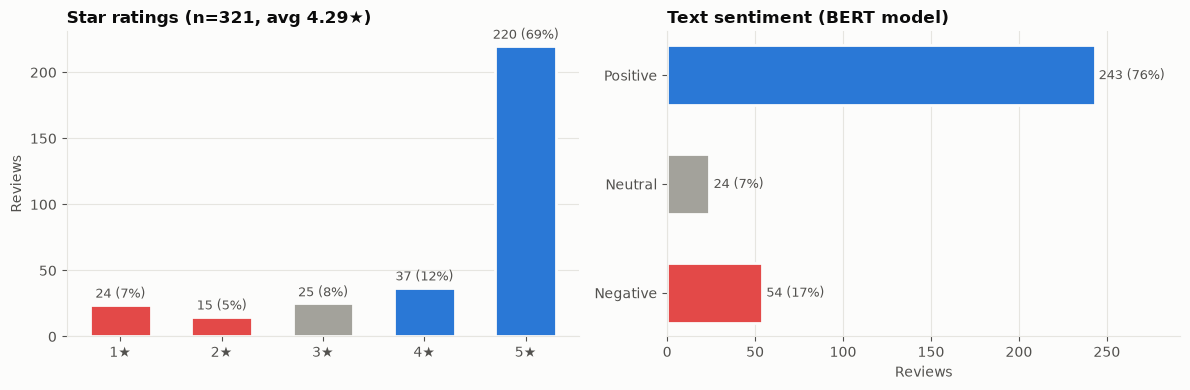

In [14]:
# Figure 1 – overview: rating distribution & overall sentiment
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rc = clean["rating"].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
bars = axes[0].bar([f"{i}★" for i in rc.index], rc.values, color=[NEG, NEG, NEU, POS, POS], width=0.6, edgecolor=SURF, linewidth=2)
axes[0].bar_label(bars, labels=[f"{v} ({v/n:.0%})" for v in rc.values], padding=3, color=INK2, fontsize=9)
axes[0].set_title(f"Star ratings (n={n}, avg {clean['rating'].astype(float).mean():.2f}★)"); axes[0].set_ylabel("Reviews")
axes[0].grid(axis="x", visible=False)

sc = clean["overall_sentiment"].value_counts().reindex(["Negative", "Neutral", "Positive"], fill_value=0)
bars = axes[1].barh(sc.index, sc.values, color=[NEG, NEU, POS], height=0.55, edgecolor=SURF, linewidth=2)
axes[1].bar_label(bars, labels=[f"{v} ({v/n:.0%})" for v in sc.values], padding=3, color=INK2, fontsize=9)
axes[1].set_title("Text sentiment (BERT model)"); axes[1].set_xlabel("Reviews"); axes[1].grid(axis="y", visible=False)
axes[1].set_xlim(0, sc.max() * 1.2)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_ratings_sentiment.png", dpi=160, bbox_inches="tight"); plt.show()

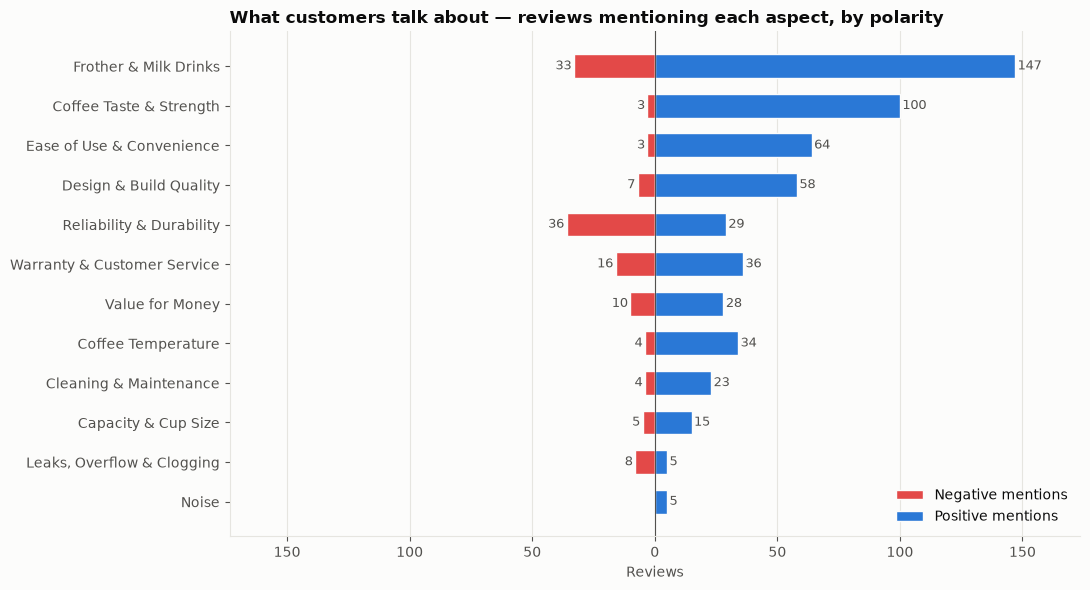

In [15]:
# Figure 2 – aspect drivers: positive vs negative mentions (diverging bar)
d = drivers.sort_values("Mentions")
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(d.index, -d["Neg"], color=NEG, height=0.6, label="Negative mentions", edgecolor=SURF, linewidth=1)
ax.barh(d.index,  d["Pos"], color=POS, height=0.6, label="Positive mentions", edgecolor=SURF, linewidth=1)
for y, (p, ng) in enumerate(zip(d["Pos"], d["Neg"])):
    if p:  ax.text(p + 1, y, str(p), va="center", fontsize=9, color=INK2)
    if ng: ax.text(-ng - 1, y, str(ng), va="center", ha="right", fontsize=9, color=INK2)
ax.axvline(0, color=INK2, linewidth=0.8)
lim = max(d["Pos"].max(), d["Neg"].max()) * 1.18
ax.set_xlim(-lim, lim); ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{abs(int(v))}"))
ax.set_title("What customers talk about — reviews mentioning each aspect, by polarity"); ax.set_xlabel("Reviews")
ax.grid(axis="y", visible=False); ax.legend(loc="lower right", frameon=False)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_aspect_drivers.png", dpi=160, bbox_inches="tight"); plt.show()

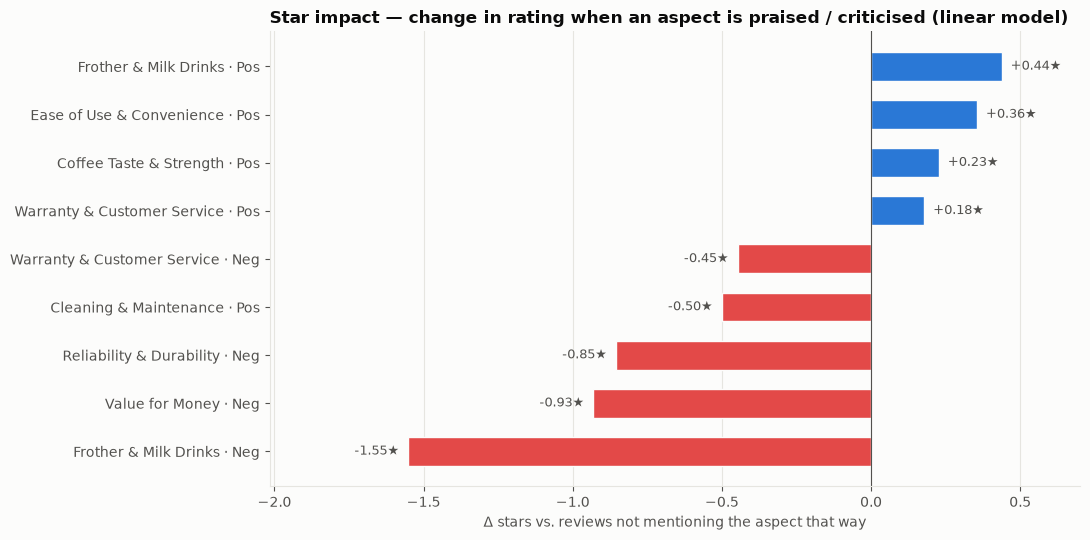

In [16]:
# Figure 3 – star impact of each aspect (regression coefficients)
imp = impact[impact.abs() >= 0.15]
fig, ax = plt.subplots(figsize=(11, 5.5))
cols = [POS if v > 0 else NEG for v in imp.values]
ax.barh([i.replace("|", " · ") for i in imp.index], imp.values, color=cols, height=0.6, edgecolor=SURF, linewidth=1)
for y, v in enumerate(imp.values):
    ax.text(v + (0.03 if v > 0 else -0.03), y, f"{v:+.2f}★", va="center", ha="left" if v > 0 else "right", fontsize=9, color=INK2)
ax.axvline(0, color=INK2, linewidth=0.8); ax.grid(axis="y", visible=False)
ax.set_xlim(imp.min() * 1.3, max(imp.max() * 1.6, 0.6))
ax.set_title("Star impact — change in rating when an aspect is praised / criticised (linear model)")
ax.set_xlabel("Δ stars vs. reviews not mentioning the aspect that way")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig3_star_impact.png", dpi=160, bbox_inches="tight"); plt.show()

,reviews,avg_rating,failure_share,recommend_rate
year,,,,
2018,12,4.33,0%,75%
2019,44,4.07,18%,73%
2020,20,3.60,40%,45%
2021,101,4.59,8%,87%
2022,50,4.20,14%,76%
2023,36,4.44,17%,78%
2024,41,4.27,20%,59%
2025,15,3.80,40%,53%
2026,2,4.00,50%,100%


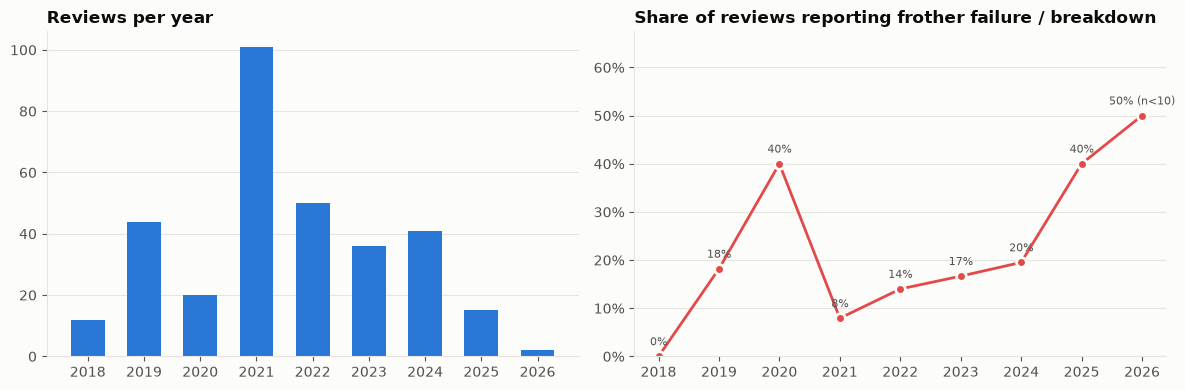

In [17]:
# Figure 4 – trend: yearly review volume, avg rating, and share of reviews reporting frother/breakdown failure
clean["year"] = clean["date"].str[:4].astype(int)
fail_ids = set(asp_rev[(asp_rev.polarity == "Neg") & asp_rev.aspect.isin(["Frother & Milk Drinks", "Reliability & Durability"])].review_id)
clean["reports_failure"] = clean["review_id"].isin(fail_ids)
yr = clean.groupby("year").agg(reviews=("review_id", "size"), avg_rating=("rating", lambda s: s.astype(float).mean()),
                               failure_share=("reports_failure", "mean"), recommend_rate=("recommended", lambda s: (s == "Yes").mean()))
display(yr.style.format({"avg_rating": "{:.2f}", "failure_share": "{:.0%}", "recommend_rate": "{:.0%}"}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(yr.index.astype(str), yr["reviews"], color=POS, width=0.6)
axes[0].set_title("Reviews per year"); axes[0].grid(axis="x", visible=False)
axes[1].plot(yr.index.astype(str), yr["failure_share"], color=NEG, linewidth=2, marker="o", markersize=7,
             markeredgecolor=SURF, markeredgewidth=2)
for x, v, k in zip(yr.index.astype(str), yr["failure_share"], yr["reviews"]):
    axes[1].annotate(f"{v:.0%}" + (" (n<10)" if k < 10 else ""), (x, v), textcoords="offset points", xytext=(0, 8),
                     ha="center", fontsize=8, color=INK2)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[1].set_ylim(0, max(yr["failure_share"].max() * 1.35, 0.1))
axes[1].set_title("Share of reviews reporting frother failure / breakdown"); axes[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig4_trend.png", dpi=160, bbox_inches="tight"); plt.show()

In [18]:
# Extra diagnostics that matter to stakeholders
hidden = clean[(clean["rating"] >= 4) & (clean["negative_aspects"] != "")]
print(f"'Hidden detractors' – 4–5★ reviews that still criticise something: {len(hidden)} ({len(hidden)/n:.0%})")
print(hidden["negative_aspects"].str.split("; ").explode().value_counts().head(6).to_string(), "\n")

repeat = clean["full_text"].str.contains(r"\b(second|2nd|third|3rd|fourth|fifth|another) (one|machine|unit|replacement|keurig)|replacement", case=False)
print(f"Reviews describing a replacement / repeat unit: {repeat.sum()} ({repeat.mean():.0%}); avg rating {clean.loc[repeat,'rating'].astype(float).mean():.2f}★")

pc = clean.groupby("promo_collected")["rating"].apply(lambda s: s.astype(float).mean())
print(f"Promotion-collected reviews: {clean['promo_collected'].sum()} ({clean['promo_collected'].mean():.0%}), avg {pc.get(True, np.nan):.2f}★ vs organic {pc.get(False, np.nan):.2f}★")
v = clean.groupby("verified_purchaser")["rating"].apply(lambda s: s.astype(float).mean())
print(f"Avg rating – verified purchasers: {v.get('Yes', np.nan):.2f}★ vs non-verified: {v.get('No', np.nan):.2f}★")
print(f"Recommend rate: {(clean['recommended']=='Yes').mean():.0%}  |  Source split: " +
      ", ".join(f"{k} {c/n:.0%}" for k, c in clean['source'].value_counts().items()))

# Most frequent words in negative sentences about the frother (root-cause hints)
from sklearn.feature_extraction.text import CountVectorizer
froth_neg = asp_long[(asp_long.aspect == "Frother & Milk Drinks") & (asp_long.sent_star_score <= 2.5)]["sentence"]
cv = CountVectorizer(ngram_range=(2, 3), stop_words="english", min_df=2).fit(froth_neg)
top = pd.Series(np.asarray(cv.transform(froth_neg).sum(axis=0)).ravel(), index=cv.get_feature_names_out()).nlargest(15)
print("\nTop phrases in negative frother sentences:\n", top.to_string())

'Hidden detractors' – 4–5★ reviews that still criticise something: 20 (6%)
negative_aspects
Reliability & Durability       9
Warranty & Customer Service    5
Frother & Milk Drinks          4
Capacity & Cup Size            3
Ease of Use & Convenience      2
Value for Money                2 

Reviews describing a replacement / repeat unit: 29 (9%); avg rating 3.48★
Promotion-collected reviews: 0 (0%), avg nan★ vs organic 4.29★
Avg rating – verified purchasers: 4.54★ vs non-verified: 3.68★
Recommend rate: 74%  |  Source split: keurig.ca 96%, bestbuy.ca 4%

Top phrases in negative frother sentences:
 frother stopped             6
coffee maker                3
frother stopped frothing    3
frother stopped working     3
make latte                  3
milk frother                3
sent replacement            3
stopped frothing            3
stopped working             3
après seulement             2
après seulement mois        2
botton light                2
botton light light          2
bought

### Summary of insights (detailed version in `Task1_Report.docx`)
The numbers in the cells above drive the report. Headline themes:
* **Satisfaction drivers:** coffee taste, convenience/ease of use, design, and — *when it works* — the latte/cappuccino frother. These
  dominate the 4–5★ reviews and the “Satisfactory & Recommended” tag.
* **Dissatisfaction drivers:** the **frother failing** (stops spinning or only heats the milk, often within weeks or months) is by far
  the #1 complaint, followed by **whole-unit breakdowns**, **leaks/overflow/clogging**, and **lukewarm coffee**. Warranty replacements
  that fail again amplify the frustration.
* **Recommendations:** root-cause the frother (motor/magnetic whisk coupling, milk-residue build-up, the electrical contact between
  the frother and the base), add a frother-care quick-start card, extend frother warranty, raise brew temperature or add a “strong/hot”
  option, and use this review stream as an always-on early-warning dashboard.

## 6. Export — Excel (formatted, multi-sheet) + CSV

In [19]:
from openpyxl.styles import PatternFill, Font, Alignment
from openpyxl.formatting.rule import FormulaRule
from openpyxl.utils import get_column_letter

export_cols = ["review_id", "title", "review_text", "date", "rating", "source", "reviewer_name",
               "overall_sentiment", "model_star_score", "sentiment_categories_str", "positive_aspects", "negative_aspects",
               "recommended", "verified_purchaser", "helpful_votes", "unhelpful_votes", "reviewer_location",
               "language", "word_count", "vader_compound", "rating_sentiment", "is_duplicate_text", "promo_collected",
               "found_in_filters", "n_filters", "matched_by", "retailer", "product_sku"]
export_cols += [c for c in clean.columns if c.startswith("sub_rating_")]
nice = {"review_id": "Primary Key (Review ID)", "title": "Title", "review_text": "Review Text", "date": "Date (YYYY-MM-DD)",
        "rating": "Rating (out of 5)", "source": "Source", "reviewer_name": "Reviewer Name",
        "overall_sentiment": "Overall Sentiment", "model_star_score": "Model Sentiment Score (1-5)",
        "sentiment_categories_str": "Sentiment Categories", "positive_aspects": "Positive Aspects",
        "negative_aspects": "Negative Aspects", "recommended": "Would Recommend", "verified_purchaser": "Verified Purchaser",
        "helpful_votes": "Helpful Votes", "unhelpful_votes": "Unhelpful Votes", "reviewer_location": "Reviewer Location",
        "language": "Language", "word_count": "Word Count", "vader_compound": "VADER Compound (baseline)",
        "rating_sentiment": "Sentiment implied by Stars", "is_duplicate_text": "Duplicate Text Flag", "promo_collected": "Promotion-collected Review",
        "found_in_filters": "Found in Filters", "n_filters": "# Filters Found In", "matched_by": "Captured By",
        "retailer": "Retailer", "product_sku": "Product SKU",
        **{c: "BestBuy Sub-rating: " + c.replace("sub_rating_", "").replace("_", " ").title() for c in clean.columns if c.startswith("sub_rating_")}}
out = clean[export_cols].rename(columns=nice)
out.to_csv(OUT_DIR / "bestbuy_keurig_reviews_sentiment.csv", index=False, encoding="utf-8-sig")

xlsx = OUT_DIR / "bestbuy_keurig_reviews_sentiment.xlsx"
driver_out = drivers.reset_index().rename(columns={"aspect": "Aspect", "Pos": "Positive mentions", "Neu": "Mixed mentions", "Neg": "Negative mentions"})
impact_out = impact.rename("Star impact (Δ★)").reset_index().rename(columns={"index": "Aspect · Polarity"})
impact_out["Aspect · Polarity"] = impact_out["Aspect · Polarity"].str.replace("|", " · ", regex=False)
with pd.ExcelWriter(xlsx, engine="openpyxl") as xw:
    out.to_excel(xw, sheet_name="Reviews_Sentiment", index=False)
    example.to_excel(xw, sheet_name="Brief_Format_Example", index=False)
    driver_out.to_excel(xw, sheet_name="Aspect_Drivers", index=False)
    impact_out.to_excel(xw, sheet_name="Star_Impact", index=False)
    yr.reset_index().to_excel(xw, sheet_name="Yearly_Trend", index=False)
    coverage.reset_index().rename(columns={"index": "Filter"}).to_excel(xw, sheet_name="Filter_Coverage", index=False)
    validation.reset_index().rename(columns={"index": "Model"}).to_excel(xw, sheet_name="Model_Validation", index=False)

    hdr_fill, hdr_font = PatternFill("solid", fgColor="1F3A5F"), Font(color="FFFFFF", bold=True)
    for ws in xw.book.worksheets:
        for c in ws[1]:
            c.fill, c.font, c.alignment = hdr_fill, hdr_font, Alignment(wrap_text=True, vertical="center")
        ws.freeze_panes = "B2"; ws.auto_filter.ref = ws.dimensions
        for i, col in enumerate(ws.iter_cols(min_row=1, max_row=min(ws.max_row, 60)), 1):
            width = max(len(str(c.value or "")) for c in col)
            ws.column_dimensions[get_column_letter(i)].width = min(max(12, width * 0.9), 60)
    ws = xw.book["Reviews_Sentiment"]
    for row in ws.iter_rows(min_row=2):
        for c in row:
            c.alignment = Alignment(wrap_text=c.column in (2, 3, 10, 11, 12), vertical="top")
    ws.column_dimensions["C"].width = 80
    rng = f"A2:{get_column_letter(ws.max_column)}{ws.max_row}"
    ws.conditional_formatting.add(rng, FormulaRule(formula=['$H2="Negative"'], fill=PatternFill("solid", fgColor="FBE3E3")))
    ws.conditional_formatting.add(rng, FormulaRule(formula=['$H2="Neutral"'],  fill=PatternFill("solid", fgColor="F0EFEC")))
    ws.conditional_formatting.add(rng, FormulaRule(formula=['$H2="Positive"'], fill=PatternFill("solid", fgColor="E3EEFB")))
    ws2 = xw.book["Brief_Format_Example"]; ws2.column_dimensions["C"].width = 90; ws2.column_dimensions["D"].width = 60
    for row in ws2.iter_rows(min_row=2):
        for c in row: c.alignment = Alignment(wrap_text=True, vertical="top")

print("Saved:", xlsx.name, "and", "bestbuy_keurig_reviews_sentiment.csv", f"({len(out)} rows, {out.shape[1]} columns)")
# also persist intermediate tables used by the report
drivers.to_csv(OUT_DIR / "aspect_drivers.csv"); impact.to_csv(OUT_DIR / "star_impact.csv"); yr.to_csv(OUT_DIR / "yearly_trend.csv")

Saved: bestbuy_keurig_reviews_sentiment.xlsx and bestbuy_keurig_reviews_sentiment.csv (321 rows, 31 columns)


## 7. Scraping challenges & how this script handles them
| Challenge | Mitigation implemented here | Production-scale extension |
|---|---|---|
| **JS-rendered content / “Show More” pagination** | Selenium renders the page, clicks “Show More” with explicit waits on card count; API path paginates `page=N` | Playwright async for parallel tabs; intercept XHR responses via CDP instead of parsing HTML |
| **Hashed / changing CSS class names** | Selectors use stable prefixes (`[class*=reviewItem_]`), schema.org `itemprop`s, `data-date`, and `id="Sort"` | Selector config file + nightly smoke test that alerts when 0 cards are parsed |
| **Rate limiting (HTTP 429) / transient 5xx** | `urllib3.Retry` with exponential back-off + `Retry-After`, random 1–2.5 s jitter, cached raw files so re-runs don’t re-hit the site | Token-bucket rate limiter per domain, off-peak scheduling, incremental scraping (only `Newest` until a known ID is seen) |
| **IP blocking** | Low volume, realistic headers, single session | Rotating residential/datacenter **proxy pool** with health-checks, sticky sessions per worker, automatic eviction of banned IPs |
| **Bot detection / fingerprinting** | Real Chrome, realistic UA/window, `AutomationControlled` flag disabled | `undetected-chromedriver` / Playwright-stealth, rotate UA + viewport, human-like scroll timing |
| **CAPTCHA** | Detect & stop (never brute-force) | Back off and retry later with a new IP; if a CAPTCHA persists, request API access/partnership. Third-party solving services exist but can breach ToS — use only where permitted |
| **Stale elements / flaky clicks** | 3-attempt retry with back-off around each click; fresh page per filter | Screenshot + HTML dump on failure for debugging |
| **Data consistency** | Union across 6 filters, de-dup by official ID / natural key, coverage table vs. site-reported total | Data-quality checks (schema, null-rate, row-count drift) in the pipeline |
| **Legal / ethical** | `robots.txt` checked programmatically, public data only, no login, no PII beyond public display names | Respect ToS, prefer official APIs/feeds, document purpose & retention |